In [1]:
import os

dataset_path = "realwaste-main/realwaste"

classes = []

for item in os.listdir(dataset_path):
    path = os.path.join(dataset_path, item)

    if os.path.isdir(path):
        classes.append(item)

print(classes)

['Paper', 'Metal', 'Cardboard', 'Food Organics', 'Glass', 'Vegetation', 'Textile Trash', 'Miscellaneous Trash', 'Plastic']


In [2]:
for class_name in classes:

    folder_path = os.path.join(dataset_path, class_name)

    images = os.listdir(folder_path)

    print(class_name, ":", len(images))

Paper : 500
Metal : 790
Cardboard : 461
Food Organics : 411
Glass : 420
Vegetation : 436
Textile Trash : 318
Miscellaneous Trash : 495
Plastic : 921


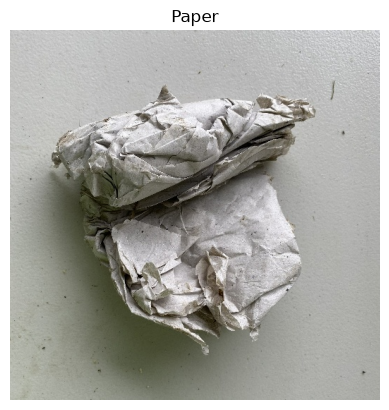

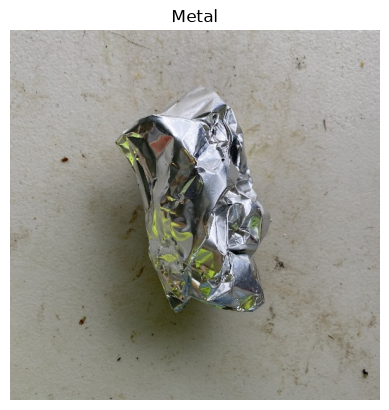

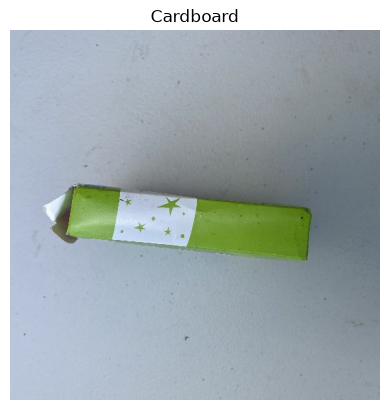

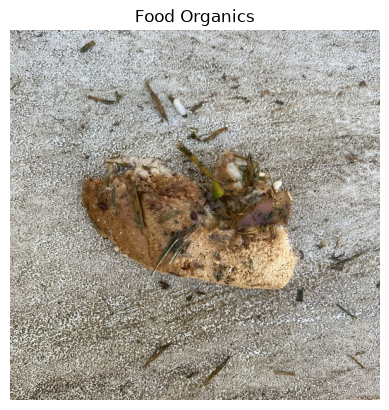

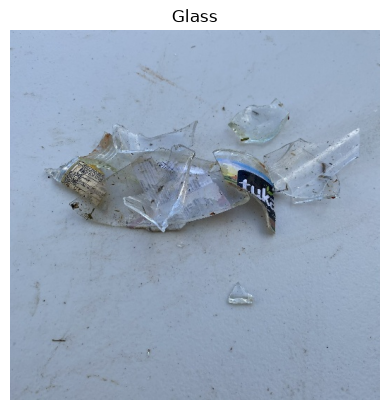

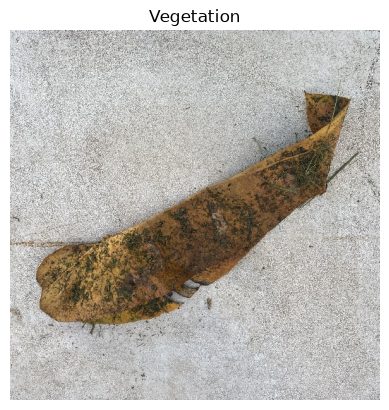

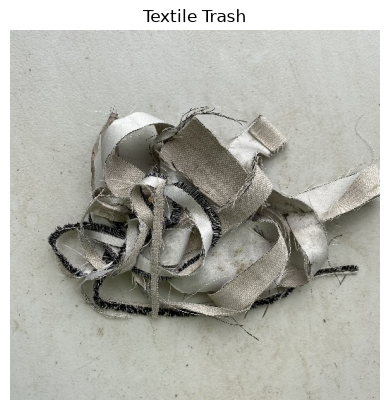

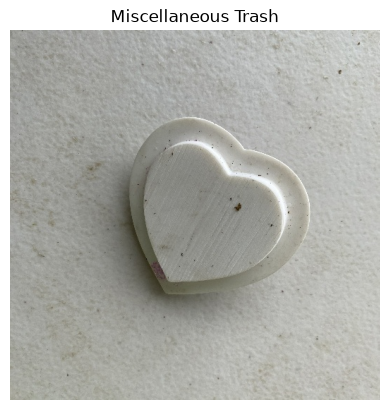

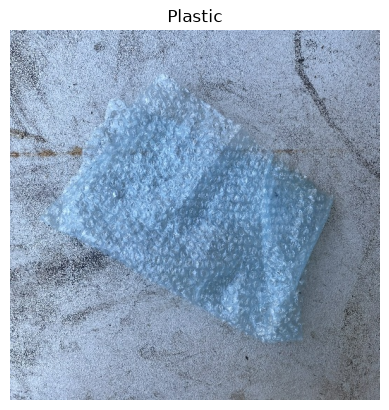

In [3]:
from PIL import Image
import matplotlib.pyplot as plt

for class_name in classes:

    folder_path = os.path.join(dataset_path, class_name)

    image_name = os.listdir(folder_path)[0]

    image_path = os.path.join(folder_path, image_name)

    image = Image.open(image_path)

    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")
    plt.show()

In [4]:
import numpy as np
from PIL import Image

In [5]:
X = []
y = []

for class_name in classes:

    folder_path = os.path.join(dataset_path, class_name)

    for image_name in os.listdir(folder_path):

        image_path = os.path.join(folder_path, image_name)

        image = Image.open(image_path)

        image = image.convert("RGB")

        image = image.resize((128, 128))

        X.append(np.array(image))
        y.append(class_name)

X = np.array(X)
y = np.array(y)

print(X.shape)
print(y.shape)

(4752, 128, 128, 3)
(4752,)


In [6]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_encoded = encoder.fit_transform(y)

print(encoder.classes_)

['Cardboard' 'Food Organics' 'Glass' 'Metal' 'Miscellaneous Trash' 'Paper'
 'Plastic' 'Textile Trash' 'Vegetation']


In [7]:
from sklearn.model_selection import train_test_split

imgs_train, imgs_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training:", len(imgs_train))
print("Testing:", len(imgs_test))

Training: 3801
Testing: 951


In [8]:
# add flipped copies of the training images (more data)
imgs_train = np.concatenate([
    imgs_train,
    imgs_train[:, :, ::-1, :],
    imgs_train[:, ::-1, :, :]
])

y_train = np.concatenate([y_train, y_train, y_train])

print("Training after flipping:", len(imgs_train), len(y_train))

Training after flipping: 11403 11403


In [9]:
from skimage.feature import hog, local_binary_pattern
from skimage.color import rgb2gray, rgb2hsv

In [10]:
def get_features(image):

    gray = rgb2gray(image)

    # shape
    shape = hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))

    # colour of the 4 quarters of the image
    hsv = rgb2hsv(image)

    quarters = [hsv[:64, :64], hsv[:64, 64:], hsv[64:, :64], hsv[64:, 64:]]

    colour = []

    for part in quarters:
        for channel in range(3):
            hist, _ = np.histogram(part[:, :, channel], bins=8, range=(0, 1), density=True)
            colour.extend(hist)
            colour.append(part[:, :, channel].mean())
            colour.append(part[:, :, channel].std())

    # texture
    lbp = local_binary_pattern((gray * 255).astype(np.uint8), 8, 1, method="uniform")
    texture, _ = np.histogram(lbp, bins=10, range=(0, 10), density=True)

    return np.concatenate([shape, colour, texture])

In [11]:
X_train = []

for image in imgs_train:
    X_train.append(get_features(image))

X_train = np.array(X_train)

print(X_train.shape)

(11403, 1894)


In [12]:
X_test = []

for image in imgs_test:
    X_test.append(get_features(image))

X_test = np.array(X_test)

print(X_test.shape)

(951, 1894)


In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [14]:
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import VotingClassifier

In [15]:
svm = SVC(C=10, probability=True, class_weight="balanced")

logreg = LogisticRegression(C=0.01, max_iter=2000)

boost = HistGradientBoostingClassifier(random_state=42)

extra = ExtraTreesClassifier(n_estimators=500, random_state=42, n_jobs=-1)

model = VotingClassifier(
    [("svm", svm), ("logreg", logreg), ("boost", boost), ("extra", extra)],
    voting="soft"
)

In [16]:
model.fit(X_train, y_train)

/Users/movvahimasameera/Desktop/innomatics/Machine Learning/image_data_project/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('svm', ...), ('logreg', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](9,)","[0,1,2,...,6,7,8]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[SVC(C=10, cla...bability=True), LogisticRegre...max_iter=2000), HistGradientB...ndom_state=42), ExtraTreesCla...ndom_state=42)]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,1894


In [17]:
from sklearn.metrics import classification_report

pred = model.predict(X_test)

print("Test Accuracy:", model.score(X_test, y_test))
print()
print(classification_report(y_test, pred, target_names=encoder.classes_))

Test Accuracy: 0.7528916929547844

                     precision    recall  f1-score   support

          Cardboard       0.77      0.78      0.78        92
      Food Organics       0.73      0.88      0.80        82
              Glass       0.89      0.74      0.81        84
              Metal       0.76      0.78      0.77       158
Miscellaneous Trash       0.68      0.48      0.56        99
              Paper       0.81      0.76      0.78       100
            Plastic       0.67      0.82      0.74       185
      Textile Trash       0.66      0.48      0.56        64
         Vegetation       0.90      0.92      0.91        87

           accuracy                           0.75       951
          macro avg       0.76      0.74      0.74       951
       weighted avg       0.75      0.75      0.75       951



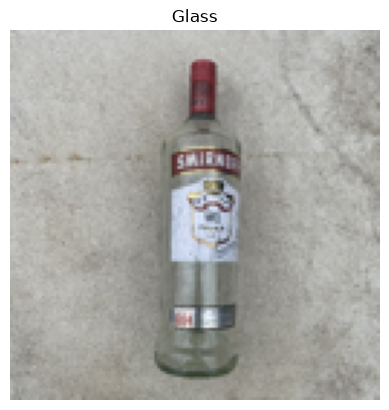

In [18]:
# predict a new image (change the path)
image_path = "realwaste-main/realwaste/Glass/Glass_1.jpg"

image = Image.open(image_path)
image = image.convert("RGB")
image = image.resize((128, 128))

features = get_features(np.array(image))
features = scaler.transform([features])

result = model.predict(features)

plt.imshow(image)
plt.title(encoder.classes_[result[0]])
plt.axis("off")
plt.show()